# CISO demand and generation-based carbon intensity

Measured findings appear below. Calendar profiles use America/Los_Angeles; stored timestamps stay UTC. Coverage describes observed generation only. Run from the repository root with the `eda` dependency group.

## Measured findings

- 50,646 UTC hours; 47 (0.093%) have no calculable intensity.
- Mean intensity 237.16, median 237.65, range 29.37–449.03 gCO2e/kWh; no values exceed configured 11–820 bounds.
- 2,615 hours are below 100 and 4,123 exceed 350 g/kWh. Mean gas share is 8.3% in low hours and 74.7% in high hours; mean solar share is 47.7% versus 0.3%. These describe observed fuel mixes, not causal effects.
- 43,472 hours have a missing included fuel cell; GEO first appears at 2025-12-16 09:00:00+00:00. Historical GEO is not imputed.
- Mean observed covered-generation fraction is 96.46%; minimum 38.97%. This excludes unknown missing generation from its denominator.
- Lowest mean local-hour intensity is 178.57 at 11:00; highest is 278.64 at 22:00 (America/Los_Angeles, DST retained).
- Demand has 0 missing cleaned hours; 53,506 observed negative fuel cells are clipped only for weighting.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
df = pd.read_parquet(root / "data/processed/CISO/hourly.parquet")
local = df.copy()
local.index = local.index.tz_convert("America/Los_Angeles")
ci = df.carbon_intensity_g_per_kwh
fuels = [c for c in df if c.startswith("gen_") and c.endswith("_mwh")]
print(f"UTC history: {df.index.min()} to {df.index.max()}; {len(df):,} hours")
display(ci.describe().to_frame())

UTC history: 2021-01-01 00:00:00+00:00 to 2026-10-12 05:00:00+00:00; 50,646 hours


,carbon_intensity_g_per_kwh
count,50599.000000
mean,237.161141
std,82.533673
min,29.366867
25%,174.966904
50%,237.653591
75%,304.559305
max,449.033038


In [2]:
hourly = local.groupby(local.index.hour).carbon_intensity_g_per_kwh.mean()
low = ci.lt(100)
high = ci.gt(350)
positive = df[fuels].clip(lower=0)
gas_share = positive.gen_ng_mwh / df.carbon_covered_generation_mwh
solar_share = positive.gen_sun_mwh / df.carbon_covered_generation_mwh
geo_start = df.gen_geo_mwh.first_valid_index()
findings = [
    f"{len(df):,} UTC hours; {ci.isna().sum():,} ({ci.isna().mean():.3%}) "
    "have no calculable intensity.",
    f"Mean intensity {ci.mean():.2f}, median {ci.median():.2f}, "
    f"range {ci.min():.2f}–{ci.max():.2f} gCO2e/kWh; "
    "no values exceed configured 11–820 bounds.",
    f"{low.sum():,} hours are below 100 and {high.sum():,} exceed 350 g/kWh. "
    f"Mean gas share is {gas_share[low].mean():.1%} in low hours and "
    f"{gas_share[high].mean():.1%} in high hours; mean solar share is "
    f"{solar_share[low].mean():.1%} versus {solar_share[high].mean():.1%}. "
    "These describe observed fuel mixes, not causal effects.",
    f"{df.carbon_missing_fuel_count.gt(0).sum():,} hours have a missing included fuel cell; "
    f"GEO first appears at {geo_start}. Historical GEO is not imputed.",
    "Mean observed covered-generation fraction is "
    f"{df.carbon_observed_coverage_fraction.mean():.2%}; "
    f"minimum {df.carbon_observed_coverage_fraction.min():.2%}. "
    "This excludes unknown missing generation from its denominator.",
    f"Lowest mean local-hour intensity is {hourly.min():.2f} at {hourly.idxmin():02d}:00; "
    f"highest is {hourly.max():.2f} at {hourly.idxmax():02d}:00 "
    "(America/Los_Angeles, DST retained).",
    f"Demand has {df.demand_mwh.isna().sum():,} missing cleaned hours; "
    f"{df.carbon_negative_generation_count.sum():,} observed negative fuel cells "
    "are clipped only for weighting.",
]
for item in findings:
    print("- " + item)
assert ci.dropna().between(11, 820).all()

- 50,646 UTC hours; 47 (0.093%) have no calculable intensity.
- Mean intensity 237.16, median 237.65, range 29.37–449.03 gCO2e/kWh; no values exceed configured 11–820 bounds.
- 2,615 hours are below 100 and 4,123 exceed 350 g/kWh. Mean gas share is 8.3% in low hours and 74.7% in high hours; mean solar share is 47.7% versus 0.3%. These describe observed fuel mixes, not causal effects.
- 43,472 hours have a missing included fuel cell; GEO first appears at 2025-12-16 09:00:00+00:00. Historical GEO is not imputed.
- Mean observed covered-generation fraction is 96.46%; minimum 38.97%. This excludes unknown missing generation from its denominator.
- Lowest mean local-hour intensity is 178.57 at 11:00; highest is 278.64 at 22:00 (America/Los_Angeles, DST retained).
- Demand has 0 missing cleaned hours; 53,506 observed negative fuel cells are clipped only for weighting.


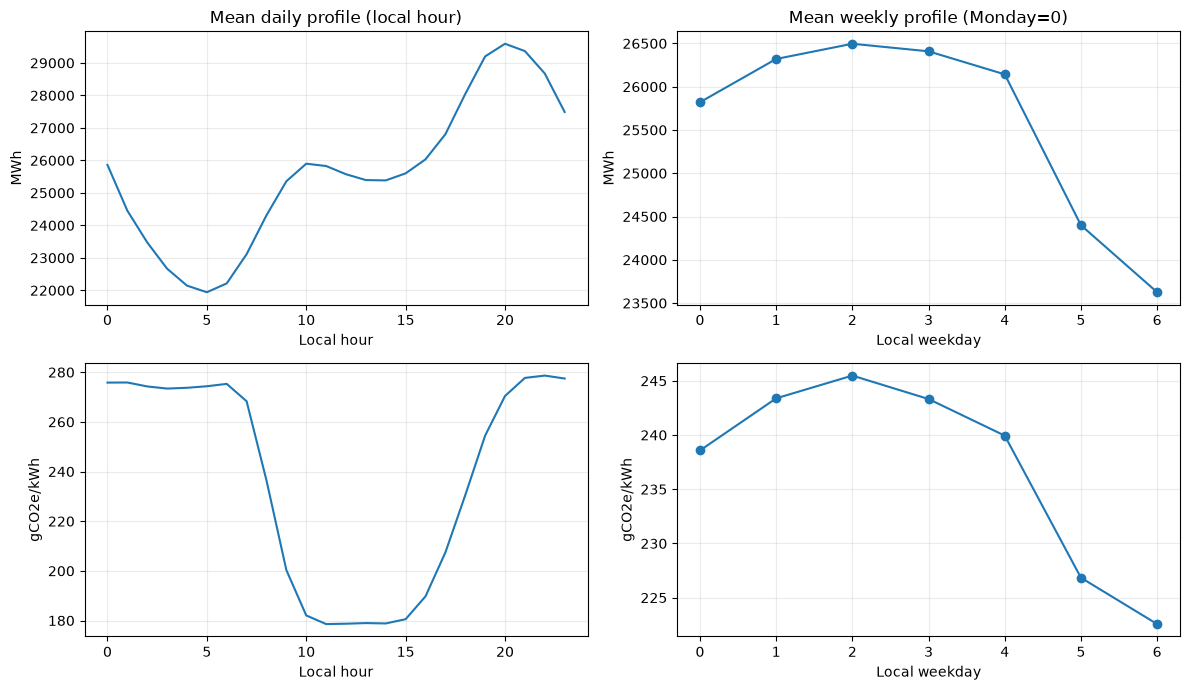

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, column in enumerate(["demand_mwh", "carbon_intensity_g_per_kwh"]):
    local.groupby(local.index.hour)[column].mean().plot(ax=axes[row, 0])
    local.groupby(local.index.dayofweek)[column].mean().plot(ax=axes[row, 1], marker="o")
    for ax in axes[row]:
        ax.set_ylabel("MWh" if row == 0 else "gCO2e/kWh")
        ax.grid(alpha=0.25)
axes[0, 0].set_title("Mean daily profile (local hour)")
axes[0, 1].set_title("Mean weekly profile (Monday=0)")
axes[0, 0].set_xlabel("Local hour")
axes[0, 1].set_xlabel("Local weekday")
axes[1, 0].set_xlabel("Local hour")
axes[1, 1].set_xlabel("Local weekday")
fig.tight_layout()
display(fig)
plt.close(fig)

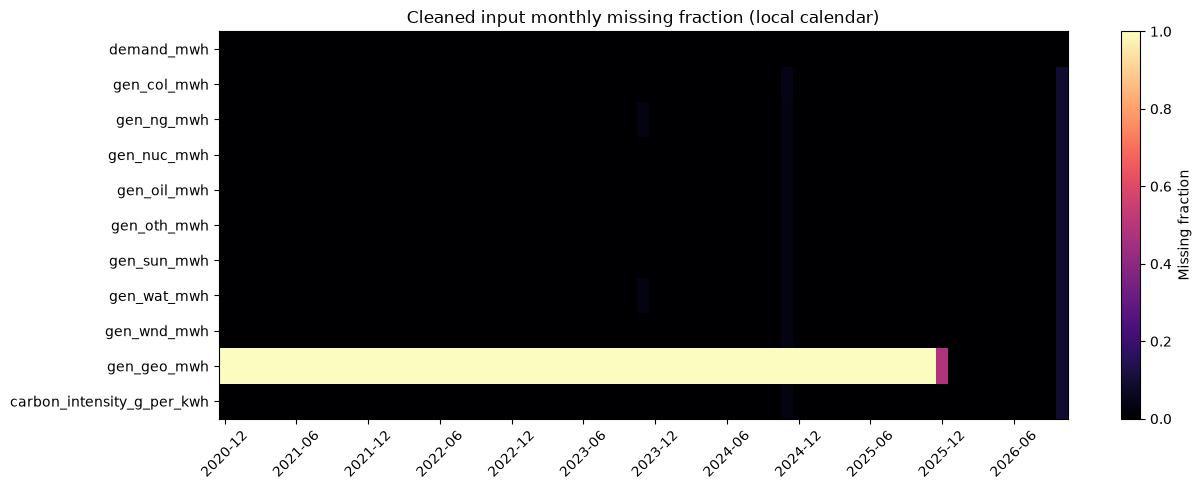

In [4]:
columns = ["demand_mwh", *fuels, "carbon_intensity_g_per_kwh"]
missing = local[columns].isna().resample("MS").mean()
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(missing.T, aspect="auto", vmin=0, vmax=1, cmap="magma")
ax.set_yticks(range(len(columns)), columns)
ticks = np.arange(0, len(missing), 6)
ax.set_xticks(ticks, [missing.index[i].strftime("%Y-%m") for i in ticks], rotation=45)
ax.set_title("Cleaned input monthly missing fraction (local calendar)")
fig.colorbar(im, ax=ax, label="Missing fraction")
fig.tight_layout()
display(fig)
plt.close(fig)

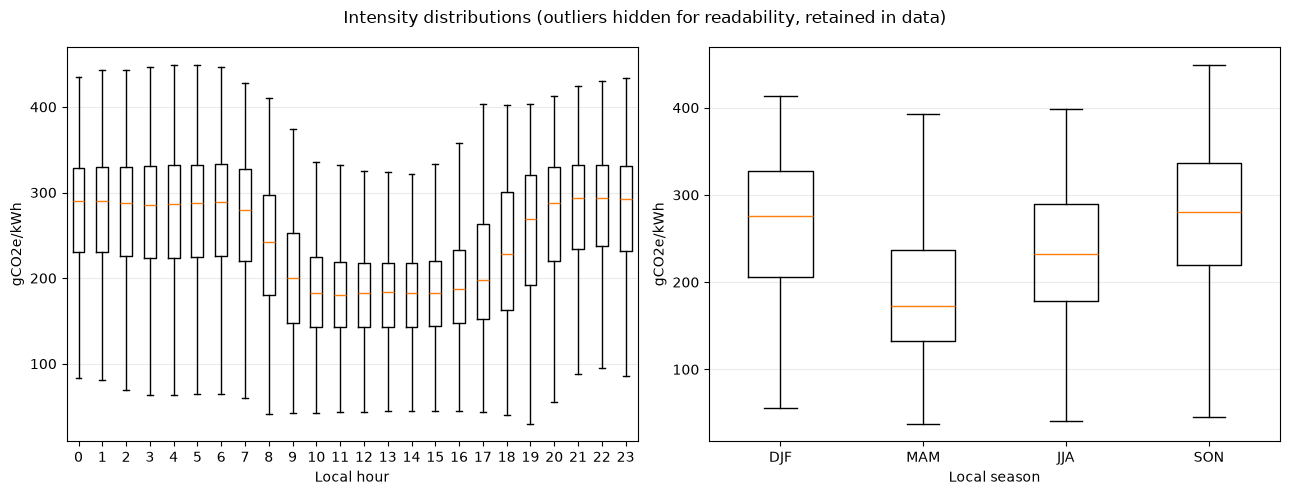

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
values = local.carbon_intensity_g_per_kwh
axes[0].boxplot(
    [values[local.index.hour == h].dropna() for h in range(24)],
    tick_labels=list(range(24)),
    showfliers=False,
)
seasons = (local.index.month % 12) // 3
axes[1].boxplot(
    [values[seasons == s].dropna() for s in range(4)],
    tick_labels=["DJF", "MAM", "JJA", "SON"],
    showfliers=False,
)
axes[0].set_xlabel("Local hour")
axes[1].set_xlabel("Local season")
for ax in axes:
    ax.set_ylabel("gCO2e/kWh")
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Intensity distributions (outliers hidden for readability, retained in data)")
fig.tight_layout()
display(fig)
plt.close(fig)